<a href="https://colab.research.google.com/github/BehroozMoniri/-home-project-/blob/main/Lunar_Lander_Q_network.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [9]:
!pip install torch torchvision numpy matplotlib gymnasium gymnasium[box2d]


Using device: cpu
Episode 20	Avg Score: -186.22	Epsilon: 0.905	Loss: 1.0729
Episode 40	Avg Score: -138.50	Epsilon: 0.818	Loss: 1.3081
Episode 60	Avg Score: -108.09	Epsilon: 0.740	Loss: 1.2817
Episode 80	Avg Score: -67.57	Epsilon: 0.670	Loss: 1.2723
Episode 100	Avg Score: -61.09	Epsilon: 0.606	Loss: 1.2933
Episode 120	Avg Score: -27.61	Epsilon: 0.548	Loss: 1.1962
Episode 140	Avg Score: -44.66	Epsilon: 0.496	Loss: 1.4161
Episode 160	Avg Score: -34.99	Epsilon: 0.448	Loss: 1.5838
Episode 180	Avg Score: -3.10	Epsilon: 0.406	Loss: 1.4480
Episode 200	Avg Score: 26.17	Epsilon: 0.367	Loss: 1.5719
Episode 220	Avg Score: 21.50	Epsilon: 0.332	Loss: 1.5491
Episode 240	Avg Score: 46.76	Epsilon: 0.300	Loss: 1.6103
Episode 260	Avg Score: 58.97	Epsilon: 0.272	Loss: 1.5581
Episode 280	Avg Score: 82.33	Epsilon: 0.246	Loss: 1.4902
Episode 300	Avg Score: 57.71	Epsilon: 0.222	Loss: 1.3131
Episode 320	Avg Score: 105.10	Epsilon: 0.201	Loss: 0.9514
Episode 340	Avg Score: 83.32	Epsilon: 0.182	Loss: 0.7912
Episo

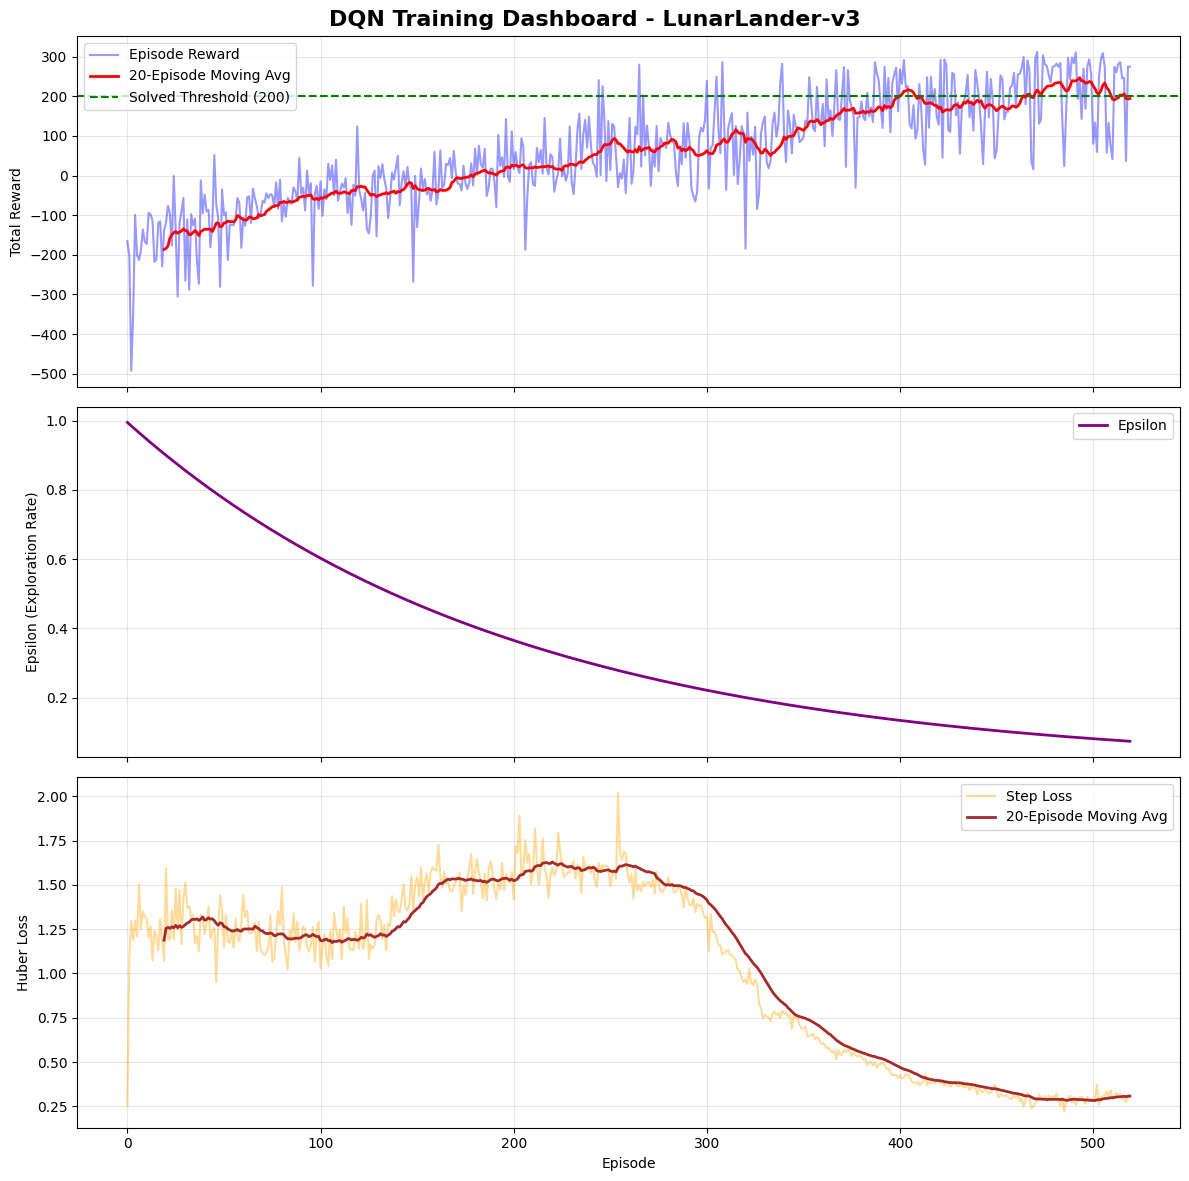

In [10]:
import gymnasium as gym
import torch
import torch.nn as nn
import torch.optim as optim
import numpy as np
import random
from collections import deque
import matplotlib.pyplot as plt

# ==========================================
# 1. Hyperparameters
# ==========================================
ENV_NAME = "LunarLander-v3" # Updated to v3
LEARNING_RATE = 5e-4
GAMMA = 0.99
BUFFER_SIZE = 100_000
BATCH_SIZE = 64
TARGET_UPDATE_FREQ = 1000
EPSILON_START = 1.0
EPSILON_END = 0.01
EPSILON_DECAY = 0.995
N_EPISODES = 1000

# Use GPU if available (Colab T4 GPU)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

torch.manual_seed(42)
np.random.seed(42)
random.seed(42)

# ==========================================
# 2. The Neural Network
# ==========================================
class QNetwork(nn.Module):
    def __init__(self, state_size, action_size):
        super(QNetwork, self).__init__()
        self.fc1 = nn.Linear(state_size, 128)
        self.fc2 = nn.Linear(128, 128)
        self.fc3 = nn.Linear(128, action_size)

    def forward(self, state):
        x = torch.relu(self.fc1(state))
        x = torch.relu(self.fc2(x))
        return self.fc3(x)

# ==========================================
# 3. Experience Replay Buffer
# ==========================================
class ReplayBuffer:
    def __init__(self, buffer_size):
        self.buffer = deque(maxlen=buffer_size)

    def push(self, state, action, reward, next_state, done):
        self.buffer.append((state, action, reward, next_state, done))

    def sample(self, batch_size):
        batch = random.sample(self.buffer, batch_size)
        states, actions, rewards, next_states, dones = zip(*batch)

        states = torch.FloatTensor(np.array(states)).to(device)
        actions = torch.LongTensor(actions).unsqueeze(1).to(device)
        rewards = torch.FloatTensor(rewards).unsqueeze(1).to(device)
        next_states = torch.FloatTensor(np.array(next_states)).to(device)
        dones = torch.FloatTensor(dones).unsqueeze(1).to(device)

        return states, actions, rewards, next_states, dones

    def __len__(self):
        return len(self.buffer)

# ==========================================
# 4. The DQN Agent
# ==========================================
class DQNAgent:
    def __init__(self, state_size, action_size):
        self.state_size = state_size
        self.action_size = action_size

        self.policy_net = QNetwork(state_size, action_size).to(device)
        self.target_net = QNetwork(state_size, action_size).to(device)
        self.target_net.load_state_dict(self.policy_net.state_dict())
        self.target_net.eval()

        self.optimizer = optim.Adam(self.policy_net.parameters(), lr=LEARNING_RATE)
        self.memory = ReplayBuffer(BUFFER_SIZE)

        self.epsilon = EPSILON_START
        self.steps_done = 0

    def select_action(self, state):
        if random.random() < self.epsilon:
            return random.randrange(self.action_size)

        with torch.no_grad():
            state = torch.FloatTensor(state).unsqueeze(0).to(device)
            q_values = self.policy_net(state)
            return q_values.argmax().item()

    def update_epsilon(self):
        self.epsilon = max(EPSILON_END, self.epsilon * EPSILON_DECAY)

    def learn(self):
        if len(self.memory) < BATCH_SIZE:
            return 0.0

        states, actions, rewards, next_states, dones = self.memory.sample(BATCH_SIZE)

        current_q_values = self.policy_net(states).gather(1, actions)

        with torch.no_grad():
            max_next_q_values = self.target_net(next_states).max(1)[0].unsqueeze(1)
            target_q_values = rewards + (GAMMA * max_next_q_values * (1 - dones))

        loss = nn.functional.smooth_l1_loss(current_q_values, target_q_values)

        self.optimizer.zero_grad()
        loss.backward()
        torch.nn.utils.clip_grad_norm_(self.policy_net.parameters(), 1.0)
        self.optimizer.step()

        self.steps_done += 1
        if self.steps_done % TARGET_UPDATE_FREQ == 0:
            self.target_net.load_state_dict(self.policy_net.state_dict())

        return loss.item()

# ==========================================
# 5. Main Training Loop
# ==========================================
def main():
    env = gym.make(ENV_NAME)
    state_size = env.observation_space.shape[0]
    action_size = env.action_space.n

    agent = DQNAgent(state_size, action_size)

    scores = []
    epsilons = []
    episode_losses = []
    best_avg_score = -float('inf') # Track the best model

    for episode in range(1, N_EPISODES + 1):
        state, _ = env.reset()
        total_reward = 0
        done = False
        episode_loss = 0
        steps = 0

        while not done:
            action = agent.select_action(state)
            next_state, reward, terminated, truncated, _ = env.step(action)
            done = terminated or truncated

            agent.memory.push(state, action, reward, next_state, done)
            loss = agent.learn()
            episode_loss += loss

            state = next_state
            total_reward += reward
            steps += 1

        agent.update_epsilon()

        scores.append(total_reward)
        epsilons.append(agent.epsilon)
        episode_losses.append(episode_loss / steps if steps > 0 else 0)

        if episode % 20 == 0:
            avg_score = np.mean(scores[-20:])
            print(f"Episode {episode}\tAvg Score: {avg_score:.2f}\tEpsilon: {agent.epsilon:.3f}\tLoss: {episode_losses[-1]:.4f}")

            # Save the BEST model, not just the last one
            if avg_score > best_avg_score and episode >= 100:
                best_avg_score = avg_score
                torch.save(agent.policy_net.state_dict(), "lunar_lander_best.pth")

            # Check for solve condition
            if np.mean(scores[-100:]) >= 200.0 and episode >= 100:
                print(f"\nEnvironment solved in {episode} episodes!")
                break

    env.close()

    # ==========================================
    # 6. Plotting
    # ==========================================
    def moving_average(a, n=20):
        if len(a) < n: return a
        ret = np.cumsum(a, dtype=float)
        ret[n:] = ret[n:] - ret[:-n]
        return ret[n - 1:] / n

    fig, axs = plt.subplots(3, 1, figsize=(12, 12), sharex=True)
    fig.suptitle('DQN Training Dashboard - LunarLander-v3', fontsize=16, fontweight='bold')

    axs[0].plot(scores, label="Episode Reward", alpha=0.4, color='blue')
    if len(scores) >= 20:
        smoothed_scores = moving_average(scores)
        axs[0].plot(range(19, len(scores)), smoothed_scores, color='red', linewidth=2, label="20-Episode Moving Avg")
    axs[0].axhline(y=200, color='green', linestyle='--', label="Solved Threshold (200)")
    axs[0].set_ylabel("Total Reward")
    axs[0].legend(loc="upper left")
    axs[0].grid(True, alpha=0.3)

    axs[1].plot(epsilons, color='purple', linewidth=2, label="Epsilon")
    axs[1].set_ylabel("Epsilon (Exploration Rate)")
    axs[1].legend(loc="upper right")
    axs[1].grid(True, alpha=0.3)

    axs[2].plot(episode_losses, color='orange', alpha=0.4, label="Step Loss")
    if len(episode_losses) >= 20:
        smoothed_loss = moving_average(episode_losses)
        axs[2].plot(range(19, len(episode_losses)), smoothed_loss, color='brown', linewidth=2, label="20-Episode Moving Avg")
    axs[2].set_xlabel("Episode")
    axs[2].set_ylabel("Huber Loss")
    axs[2].legend(loc="upper right")
    axs[2].grid(True, alpha=0.3)

    plt.tight_layout()
    plt.savefig("lunar_lander_dashboard.png", dpi=300)
    plt.show()

if __name__ == "__main__":
    main()

# New section

In [11]:
import gymnasium as gym
import torch
import torch.nn as nn
from gymnasium.wrappers import RecordVideo
import glob
import os

# Recreate the Network architecture
class QNetwork(nn.Module):
    def __init__(self, state_size, action_size):
        super(QNetwork, self).__init__()
        self.fc1 = nn.Linear(state_size, 128)
        self.fc2 = nn.Linear(128, 128)
        self.fc3 = nn.Linear(128, action_size)

    def forward(self, state):
        x = torch.relu(self.fc1(state))
        x = torch.relu(self.fc2(x))
        return self.fc3(x)

# Setup environment
env = gym.make("LunarLander-v3", render_mode="rgb_array")
env = RecordVideo(env, video_folder="videos", episode_trigger=lambda x: True)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = QNetwork(env.observation_space.shape[0], env.action_space.n).to(device)

# LOAD THE BEST MODEL
model.load_state_dict(torch.load("lunar_lander_best.pth", map_location=device))
model.eval()

# Run one episode
state, _ = env.reset()
total_reward = 0
done = False

while not done:
    state_tensor = torch.FloatTensor(state).unsqueeze(0).to(device)
    with torch.no_grad():
        action = model(state_tensor).argmax().item()

    state, reward, terminated, truncated, _ = env.step(action)
    total_reward += reward
    done = terminated or truncated

env.close()
print(f"Episode finished with a total reward of: {total_reward:.2f}")

# Display video
video_files = glob.glob("videos/*.mp4")
if video_files:
    from IPython.display import Video
    Video(video_files[0], embed=True, width=600)

/usr/local/lib/python3.13/dist-packages/gymnasium/wrappers/rendering.py:298: UserWarning: WARN: Overwriting existing videos at /content/videos folder (try specifying a different `video_folder` for the `RecordVideo` wrapper if this is not desired)
  logger.warn(


Episode finished with a total reward of: 279.70
Video saved to: videos/rl-video-episode-0.mp4


In [12]:
from google.colab import files
files.download(video_files[0])

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>